# Best fitted line using objects

We fit the same line as in the previous notebooks, but now we pack the whole analysis (estimation, intervals, confidence region and residual diagnostics) in a class, so that it can be reused with any dataset with one covariate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import beta, t, f, gaussian_kde
from statsmodels.stats.outliers_influence import OLSInfluence
from ipywidgets import interact, FloatSlider

## The class

The class `slr` (simple linear regression) receives a data frame with columns `x` and `y`. Each method does one step of the analysis, `main` runs all of them.

In [2]:
class slr:
    # Colors shared by all the plots
    point_color = '#c1121f'
    line_color  = '#1f4e79'
    ci_color    = '#7fb8d8'
    pi_color    = '#cfe8f3'
    ref_color   = '#555555'

    def __init__(self, dat, n_grid=100, alpha=0.05):
        self.p = 2
        self.n = dat.shape[0]
        self.n_grid = n_grid
        self.alpha = alpha
        self.Y = np.asarray(dat['y'], dtype=float)
        self.x = np.asarray(dat['x'], dtype=float)
        self.X = np.column_stack([np.ones(self.n), self.x])

    # ---------- estimation ----------
    def OLS(self):
        self.results = sm.OLS(self.Y, self.X).fit()
        self.s2 = self.results.scale
        self.beta = np.asarray(self.results.params)
        self.fitted = np.asarray(self.results.fittedvalues)
        self.resid = np.asarray(self.results.resid)

    def summary(self):
        print(self.results.summary2())

    def intervals(self, x_grid, alpha=None):
        # Confidence interval for the mean and prediction interval on a grid
        alpha = self.alpha if alpha is None else alpha
        X, n, p = self.X, self.n, self.p
        X_grid = np.column_stack([np.ones(len(x_grid)), x_grid])
        Y_grid_hat = X_grid @ self.beta
        h_grid = np.diag(X_grid @ np.linalg.solve(X.T @ X, X_grid.T))
        q = t.ppf(1-alpha/2, n-p)
        aux_t_conf = np.sqrt(self.s2 * h_grid)
        aux_t_pred = np.sqrt(self.s2 * (1 + h_grid))
        return (Y_grid_hat,
                Y_grid_hat - q*aux_t_conf, Y_grid_hat + q*aux_t_conf,
                Y_grid_hat - q*aux_t_pred, Y_grid_hat + q*aux_t_pred)

    def conf_region(self, b0, b1):
        # Quadratic form (b-beta)' X'X (b-beta) / (p s^2), evaluated on a grid
        A = self.X.T @ self.X
        d0 = b0 - self.beta[0]
        d1 = b1 - self.beta[1]
        return (A[0,0]*d0**2 + 2*A[0,1]*d0*d1 + A[1,1]*d1**2) / (self.p*self.s2)

    def residual_analysis(self):
        self.influence = OLSInfluence(self.results).summary_frame()
        self.h = np.asarray(self.influence['hat_diag'])
        self.student_resid = np.asarray(self.influence['student_resid'])

    def qq_t_interval(self, k):
        # Pointwise interval for the k-th order statistic of n values from a t distribution
        n = self.n
        df = self.n - self.p - 1
        a1 = beta.ppf(self.alpha/2, k, n+1-k)
        a2 = beta.ppf(1-self.alpha/2, k, n+1-k)
        return t.ppf(a1, df), t.ppf(a2, df)

    # ---------- plots ----------
    def _points(self, ax, x, y, label=None):
        ax.plot(x, y, 'o', color=self.point_color, markersize=6,
                markeredgecolor='white', markeredgewidth=0.5, label=label)

    def _finish(self, ax, title, xlabel, ylabel, legend=True):
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        if legend:
            ax.legend(loc='best', frameon=False)
        ax.grid(True, alpha=0.25)

    def _label_points(self, ax, x, y, idx, offset=(7, 7), ha='left'):
        for i in idx:
            ax.annotate(f'obs. {i+1}', (x[i], y[i]), xytext=offset, textcoords='offset points',
                        fontsize=10, color='#333333', ha=ha)

    def plot_regression(self, alpha=None, ax=None):
        alpha = self.alpha if alpha is None else alpha
        show = ax is None
        if ax is None:
            fig, ax = plt.subplots(figsize=(10, 7.5))

        margin = 0.05*(self.x.max() - self.x.min())
        x_grid = np.linspace(self.x.min() - margin, self.x.max() + margin, self.n_grid)
        Y_grid_hat, ci_lower, ci_upper, pi_lower, pi_upper = self.intervals(x_grid, alpha)

        ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
        pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
        ax.fill_between(x_grid, pi_lower, pi_upper, color=self.pi_color, label=pi_label)
        ax.fill_between(x_grid, ci_lower, ci_upper, color=self.ci_color, alpha=0.7, label=ci_label)
        ax.plot(x_grid, Y_grid_hat, color=self.line_color, lw=2, label='Fitted line')
        self._points(ax, self.x, self.Y, label='Observed data')

        self._finish(ax, 'Estimated regression function', 'x', 'y')
        if show:
            plt.show()

    def plot_confidence_region(self):
        p, n, alpha = self.p, self.n, self.alpha
        ci = np.asarray(self.results.conf_int(alpha=alpha))
        (b0_low, b0_upp), (b1_low, b1_upp) = ci

        # The joint region is wider than the individual intervals: its half-widths are
        # sqrt(p F s^2 (X'X)^{-1}_jj), we add a 15% margin to draw it complete
        level = f.ppf(1-alpha, p, n-p)
        half = 1.15*np.sqrt(p*level*self.s2*np.diag(np.linalg.inv(self.X.T @ self.X)))
        b0_grid = np.linspace(self.beta[0]-half[0], self.beta[0]+half[0], 4*self.n_grid)
        b1_grid = np.linspace(self.beta[1]-half[1], self.beta[1]+half[1], 4*self.n_grid)
        B0, B1 = np.meshgrid(b0_grid, b1_grid)
        z = self.conf_region(B0, B1)

        fig, ax = plt.subplots(figsize=(10, 7.5))
        ax.contourf(B0, B1, z, levels=[0, level], colors=[self.ci_color], alpha=0.7)
        ax.contour(B0, B1, z, levels=[level], colors=[self.line_color], linewidths=2)
        ax.plot([b0_low, b0_upp, b0_upp, b0_low, b0_low], [b1_low, b1_low, b1_upp, b1_upp, b1_low],
                '--', color=self.ref_color, lw=1.5)
        self._points(ax, [self.beta[0]], [self.beta[1]])

        conf = f'{(1 - alpha) * 100:.0f}%'
        ax.annotate(f'{conf} joint confidence region', (self.beta[0], self.beta[1]), xytext=(60, 60),
                    textcoords='offset points', color=self.line_color, fontsize=11,
                    arrowprops=dict(arrowstyle='-', color=self.line_color, lw=1))
        ax.annotate(f'Individual {conf} confidence intervals', (b0_low, b1_upp), xytext=(4, 6),
                    textcoords='offset points', color=self.ref_color, fontsize=11)
        self._finish(ax, r'Confidence region and intervals for $\beta$', r'$\beta_0$', r'$\beta_1$', legend=False)
        plt.show()

    def resid_density_plot(self):
        n, p = self.n, self.p
        r = self.student_resid
        r_grid = np.linspace(min(r.min(), -3.5), max(r.max(), 3.5), self.n_grid)

        fig, ax = plt.subplots(figsize=(10, 7.5))
        ax.hist(r, bins='auto', density=True, color=self.pi_color, edgecolor='white', linewidth=2,
                label='Histogram')
        ax.plot(r_grid, gaussian_kde(r)(r_grid), '--', color=self.ref_color, lw=1.5, label='Kernel estimator')
        ax.plot(r_grid, t.pdf(r_grid, df=n-p-1), color=self.line_color, lw=2, label=f'$t_{{{n-p-1}}}$ density')
        ax.plot(r, np.zeros(n), '|', color=self.point_color, markersize=14, label='Studentized residuals')
        self._finish(ax, 'Histogram and t density for the studentized residuals', 'Studentized residual', 'Density')
        plt.show()

    def resid_qq_plot(self):
        n, p = self.n, self.p
        k = np.arange(1, n+1)
        order = np.argsort(self.student_resid)
        r_sorted = self.student_resid[order]
        q_theo = t.ppf(k/(n+1), df=n-p-1)
        qq_lower, qq_upper = self.qq_t_interval(k)
        conf = f'{(1 - self.alpha) * 100:.0f}%'

        fig, ax = plt.subplots(figsize=(10, 7.5))
        ax.fill_between(q_theo, qq_lower, qq_upper, color=self.pi_color, label=f'{conf} pointwise interval')
        ax.plot(q_theo, q_theo, color=self.line_color, lw=2, label='Identity line')
        self._points(ax, q_theo, r_sorted, label='Studentized residuals')
        outside = np.where((r_sorted < qq_lower) | (r_sorted > qq_upper))[0]
        for j in outside:
            ax.annotate(f'obs. {order[j]+1}', (q_theo[j], r_sorted[j]), xytext=(7, 7),
                        textcoords='offset points', fontsize=10, color='#333333')
        self._finish(ax, 'QQ plot for the studentized residuals',
                     f'Theoretical quantiles of $t_{{{n-p-1}}}$', 'Ordered studentized residuals')
        plt.show()

    def fitted_vs_resid_plot(self):
        fig, ax = plt.subplots(figsize=(10, 7.5))
        ax.axhline(0, color=self.line_color, lw=2)
        ax.vlines(self.fitted, 0, self.resid, color=self.ref_color, lw=1, alpha=0.5)
        self._points(ax, self.fitted, self.resid)
        # Label the observations with the largest studentized residuals
        self._label_points(ax, self.fitted, self.resid, np.argsort(-np.abs(self.student_resid))[:3])
        self._finish(ax, 'Residuals vs fitted values', 'Fitted values', 'Residuals', legend=False)
        plt.show()

    def resid_vs_previous_resid_plot(self):
        e = self.resid
        fig, ax = plt.subplots(figsize=(10, 7.5))
        ax.axhline(0, color=self.ref_color, lw=1)
        ax.axvline(0, color=self.ref_color, lw=1)
        self._points(ax, e[:-1], e[1:])
        corr = np.corrcoef(e[:-1], e[1:])[0, 1]
        self._finish(ax, f'Residuals vs previous residuals (correlation = {corr:.2f})',
                     r'$e_{i-1}$', r'$e_i$', legend=False)
        plt.show()

    def out_resid_vs_resid_plot(self):
        e = self.resid
        out_resid = e/(1-self.h)
        lim = np.array([min(e.min(), out_resid.min()), max(e.max(), out_resid.max())])

        fig, ax = plt.subplots(figsize=(10, 7.5))
        ax.plot(lim, lim, '--', color=self.line_color, lw=2, label='Identity line')
        self._points(ax, e, out_resid, label='Observations')
        # Label the observations farthest from the identity line
        self._label_points(ax, e, out_resid, np.argsort(-np.abs(out_resid-e))[:2], offset=(9, -12))
        self._finish(ax, 'Residuals vs outer residuals', r'Residuals $e_i$', r'Outer residuals $e_i/(1-h_{ii})$')
        plt.show()

    def leverage_plot(self):
        n, p = self.n, self.p
        idx = np.arange(1, n+1)
        fig, ax = plt.subplots(figsize=(10, 7.5))
        ax.vlines(idx, 0, self.h, color=self.ref_color, lw=1, alpha=0.5)
        ax.axhline(2*p/n, ls='--', color=self.line_color, lw=2, label=r'Threshold $2p/n$')
        self._points(ax, idx, self.h, label=r'Leverage $h_{ii}$')
        self._label_points(ax, idx, self.h, np.where(self.h > 2*p/n)[0], offset=(-9, -3), ha='right')
        self._finish(ax, 'Leverage of each observation', 'Observation', r'$h_{ii}$')
        plt.show()

    def main(self):
        self.OLS()
        self.summary()
        self.plot_regression()
        self.plot_confidence_region()
        self.residual_analysis()
        self.resid_density_plot()
        self.resid_qq_plot()
        self.fitted_vs_resid_plot()
        self.resid_vs_previous_resid_plot()
        self.out_resid_vs_resid_plot()
        self.leverage_plot()

## The data

In [3]:
dat = pd.DataFrame({
    'x': [100, 89, 89, 92, 78, 101, 90, 82, 95, 108, 111, 112, 125, 123, 100, 102, 112, 112, 100, 107, 103, 129, 118, 149],
    'y': [709, 740, 586, 806, 694, 760, 664, 509, 619, 652, 772, 896, 742, 831, 667, 772, 838, 679, 889, 690, 698, 860, 799, 882]
    })
dat = dat/10

## Fitting the line

`slr(dat).main()` would run the whole analysis at once. Here we call the methods one by one.

In [4]:
model = slr(dat)
model.OLS()
model.summary()

                 Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.354   
Dependent Variable: y                AIC:                170.1473
Date:               2026-10-12 14:27 BIC:                172.5034
No. Observations:   24               Log-Likelihood:     -83.074 
Df Model:           1                F-statistic:        13.61   
Df Residuals:       22               Prob (F-statistic): 0.00128 
R-squared:          0.382            Scale:              64.841  
-------------------------------------------------------------------
            Coef.    Std.Err.     t      P>|t|     [0.025    0.975]
-------------------------------------------------------------------
const      33.4819    11.0983   3.0168   0.0063   10.4653   56.4984
x1          3.8458     1.0424   3.6893   0.0013    1.6839    6.0077
-----------------------------------------------------------------
Omnibus:              0.575        Durbin-Watson:           2.382
Prob(Omnibus):   

In [5]:
print('beta:', model.beta)
print('s2:  ', model.s2)

beta: [33.48189264  3.84580363]
s2:   64.84089082745449


## Confidence and prediction intervals

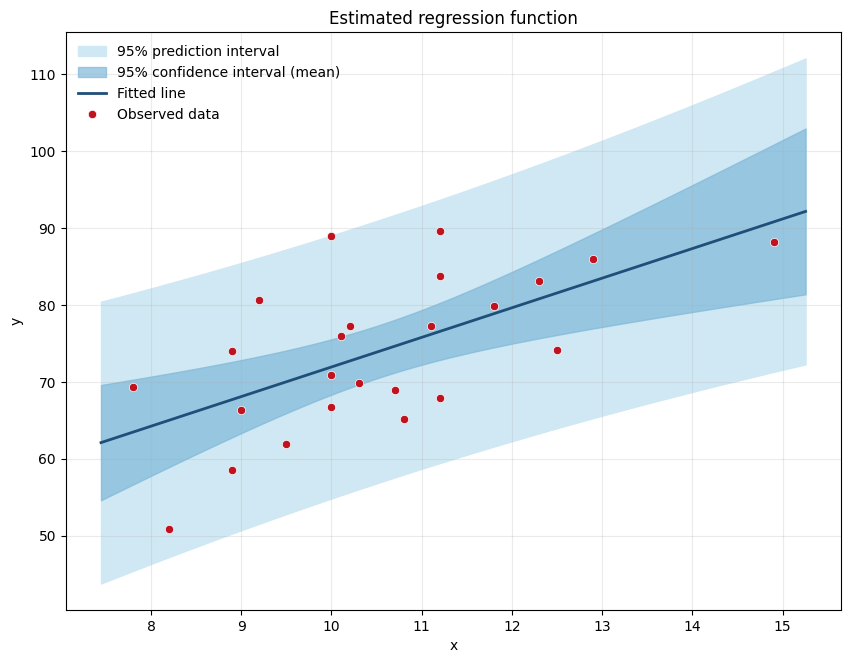

In [6]:
model.plot_regression()

Move the slider to see how both bands change with the significance level $\alpha$ (this cell needs a running kernel).

In [7]:
interact(lambda alpha: model.plot_regression(alpha=alpha),
         alpha=FloatSlider(value=0.05, min=0.01, max=0.20, step=0.01, description='alpha'));

interactive(children=(FloatSlider(value=0.05, description='alpha', max=0.2, min=0.01, step=0.01), Output()), _…

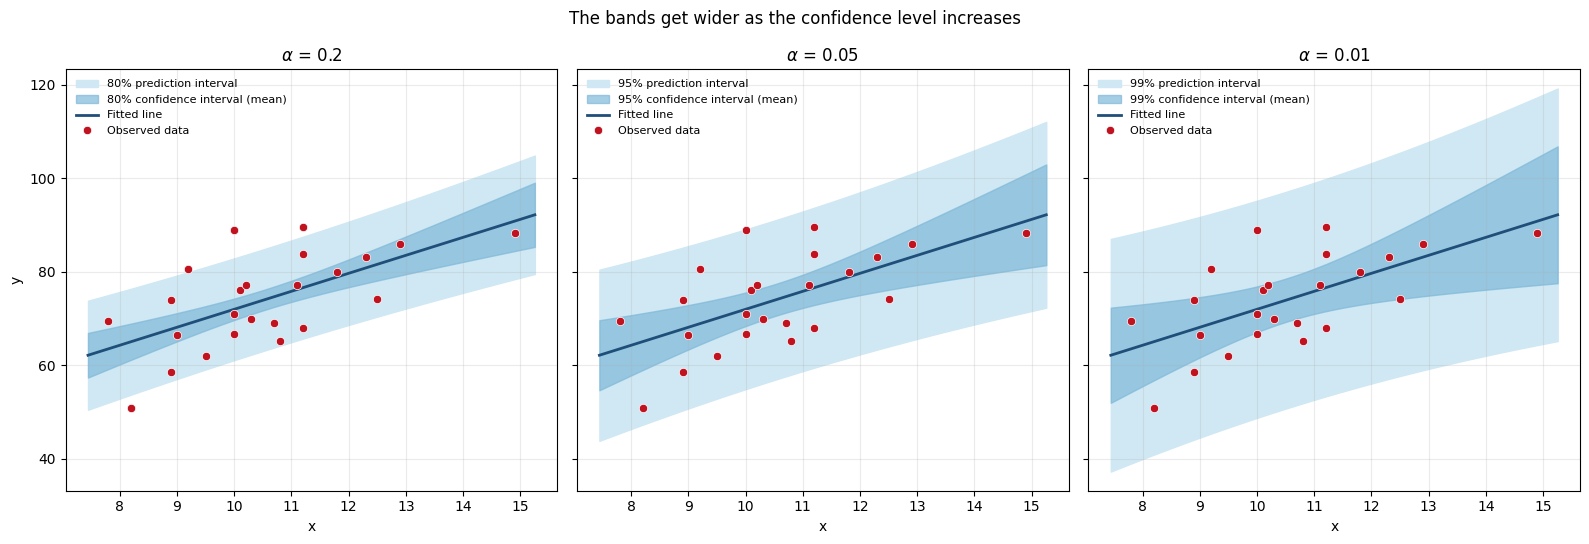

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
for ax, alpha in zip(axes, [0.20, 0.05, 0.01]):
    model.plot_regression(alpha=alpha, ax=ax)
    ax.set_title(rf'$\alpha$ = {alpha}')
    ax.legend(loc='upper left', frameon=False, fontsize=8)
for ax in axes[1:]:
    ax.set_ylabel('')
fig.suptitle('The bands get wider as the confidence level increases')
plt.tight_layout()

## Confidence region for the parameters

The joint confidence region for $\beta$ is the ellipse
$$\frac{(b-\hat\beta)^TX^TX(b-\hat\beta)}{p\,s^2} \leq F_{p,n-p}^{1-\alpha},$$
while the rectangle is built with the individual confidence intervals. The estimators of the intercept and the slope are negatively correlated, so there are points in the rectangle that are not plausible values for $\beta$.

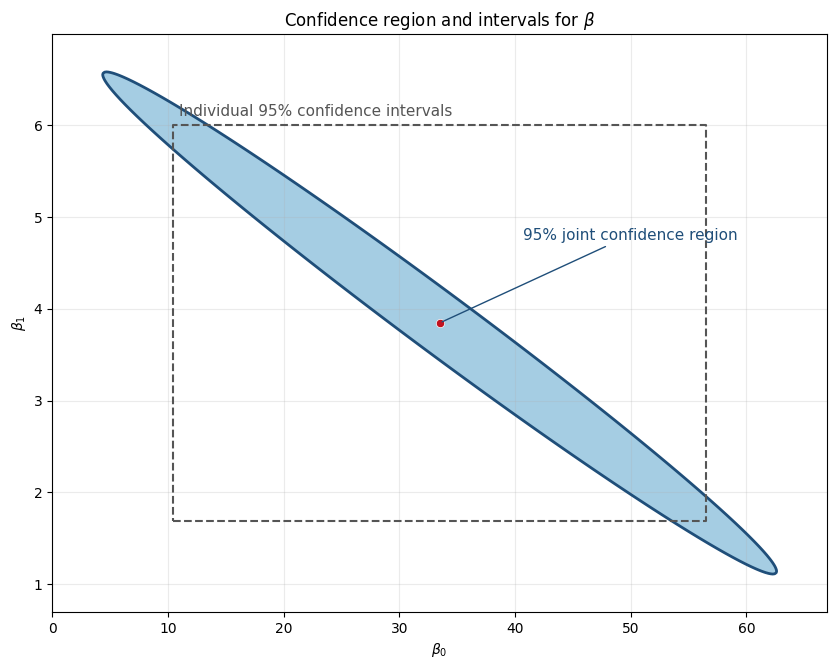

In [9]:
model.plot_confidence_region()

## Residual analysis

If the model is correct, the (externally) studentized residuals follow a $t_{n-p-1}$ distribution.

In [10]:
model.residual_analysis()
model.influence.head()

,dfb_const,dfb_x1,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
0,-0.012969,0.009067,0.000425,-0.132247,0.046359,-0.029158,-0.129258,-0.028499
1,0.202548,-0.178880,0.031476,0.817184,0.086148,0.250902,0.810796,0.248941
2,-0.298492,0.263613,0.066010,-1.183407,0.086148,-0.363345,-1.194855,-0.366860
3,0.324621,-0.278725,0.087775,1.512441,0.071274,0.418988,1.561050,0.432454
4,0.332141,-0.309101,0.064784,0.805386,0.166493,0.359955,0.798732,0.356981


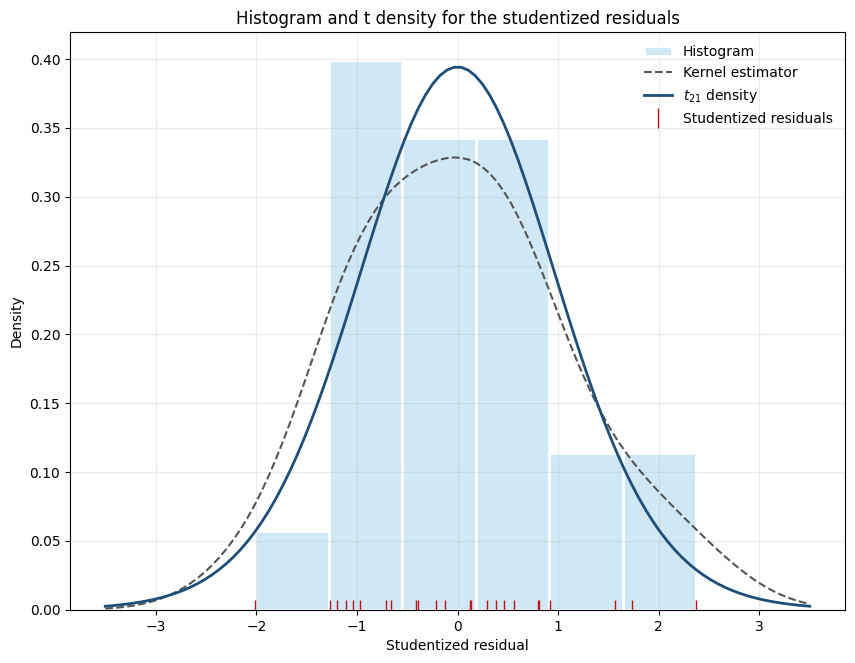

In [11]:
model.resid_density_plot()

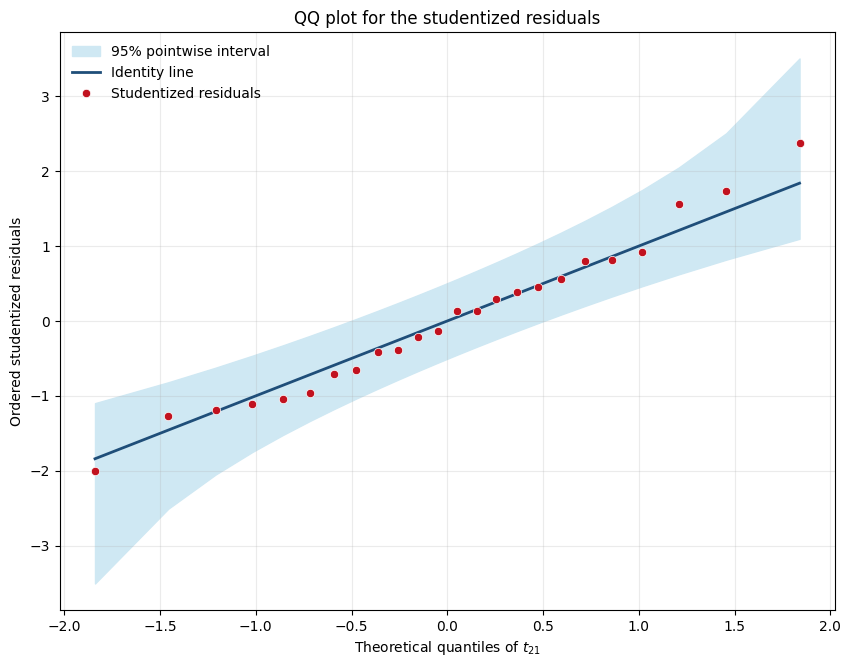

In [11]:
model.resid_qq_plot()

The residuals should not show any structure against the fitted values, nor against the previous residual.

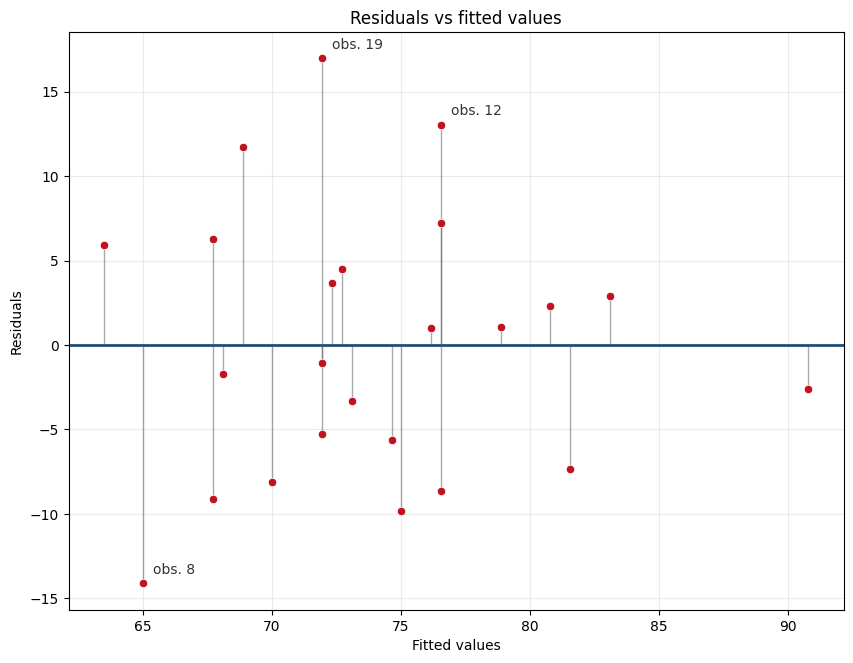

In [12]:
model.fitted_vs_resid_plot()

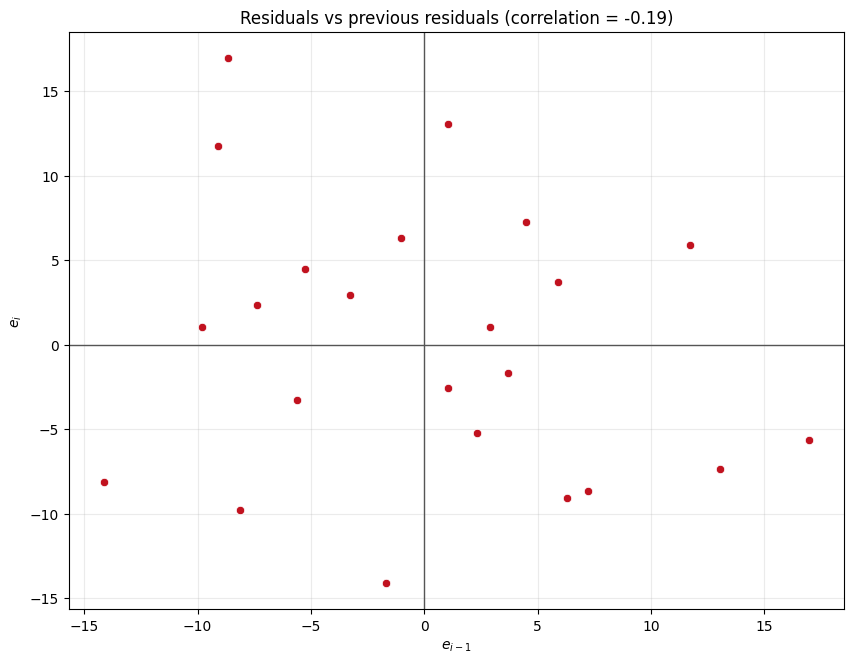

In [14]:
model.resid_vs_previous_resid_plot()

The outer residual $e_i/(1-h_{ii})$ is the error we make predicting the $i$-th observation with the line fitted without it. It is far from the usual residual only for observations with a high leverage $h_{ii}$.

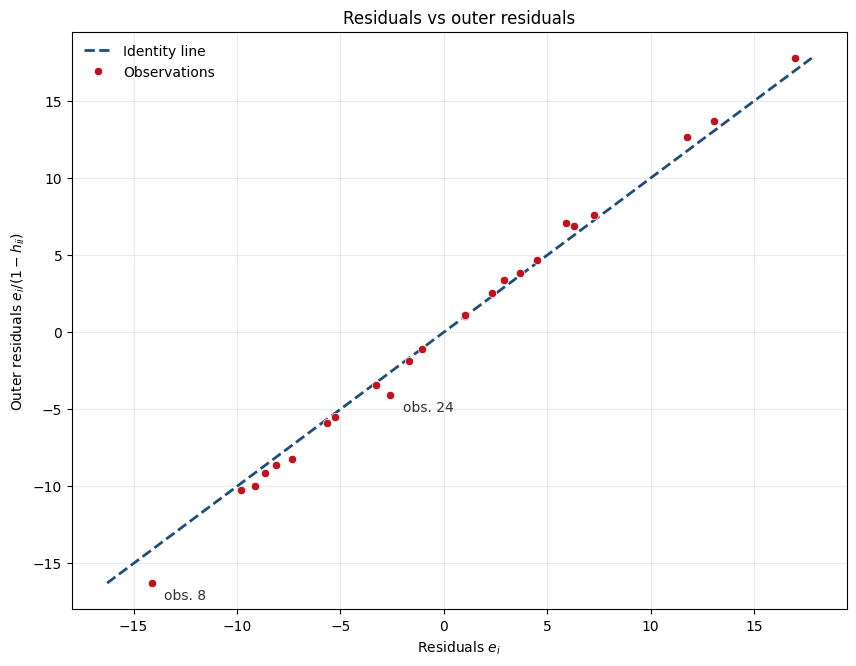

In [15]:
model.out_resid_vs_resid_plot()

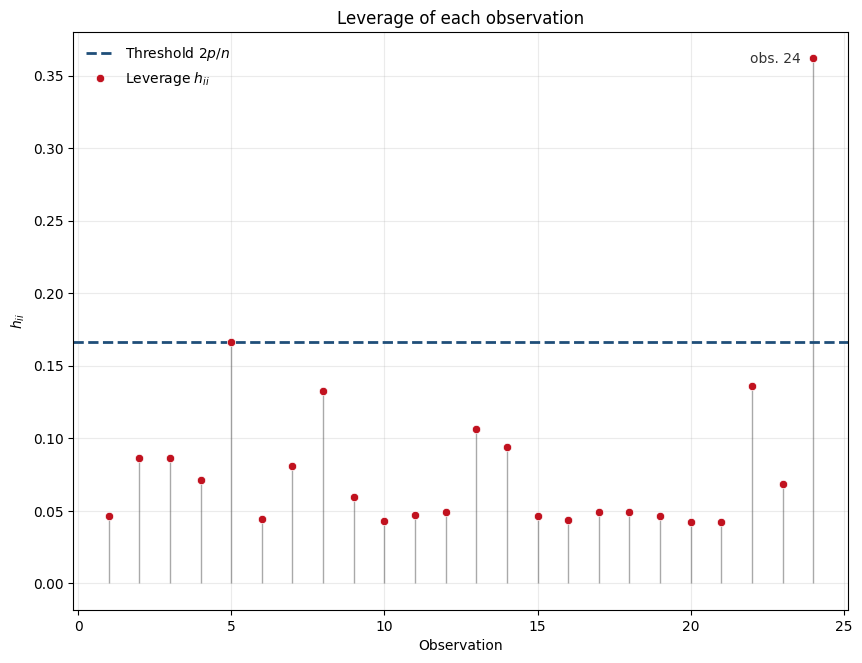

In [16]:
model.leverage_plot()